# Road Accident Predictions with Graph Neural Networks

## 1. Introduction

### 1.1 Motivation and Scope

Road accidents impose substantial human and economic costs, averaging 2.7% of GDP in high-income countries (Wijnen & Stipdonk, 2016). In Delaware, 96.5% of road-months have no recorded accident, while 10% of roads account for 70.6% of accidents. Identifying high-risk roads could help agencies prioritise inspections and safety improvements, but sparse outcomes and incomplete traffic and road information make prediction difficult. Connected roads share traffic and surroundings, motivating a graph representation with intersections as nodes and road segments as edges.

We study next-month accident occurrence and counts on Delaware physical-road proxies using ML4RoadSafety (Nippani et al., 2023). We reproduce selected MLP and edge-aware GraphSAGE baselines with adaptations and extend the comparison to established GatedGCN and Graph Transformer architectures, which the original paper did not evaluate. Each model is tested with baseline inputs, additional OpenStreetMap (OSM) context, accident history, and both additions.

The main comparisons share chronological evaluation and fixed Node2Vec embeddings (Grover & Leskovec, 2016). Thus, even MLP receives structural information, although it performs no message passing. Changes to features, embeddings and target aggregation make this a modified reproduction; published scores are contextual references.

### 1.2 Research Questions

1. **Road context:** Do additional OSM road and surrounding-area attributes improve prediction, and which feature groups do fitted models rely on most?
2. **Accident history:** Do past accidents on a road and its neighbours improve next-month occurrence and count prediction?
3. **Model architecture:** How do MLP, GraphSAGE, GatedGCN and Graph Transformer compare within each input configuration?

### 1.3 Contributions

We develop and validate OSM matching and feature construction, build past-only own-road and neighbour-history features, and evaluate their contributions across four architectures and two tasks under a shared protocol. An interactive map supports exploration of recorded and predicted road risk. The contribution is the implemented pipelines and controlled empirical comparison, rather than new architectures or the introduction of road context and accident history as predictive concepts.


## 2. Related Work

### 2.1 Accident Prediction and Road Context

Accident prediction spans statistical and neural approaches. Ma et al. (2017) modelled crash frequency using negative-binomial models with spatial and temporal effects; Guerra et al. (2022) compared regression and machine-learning methods and identified traffic volume as an important predictor. Kashifi et al. (2023) combined convolutional, recurrent and feedforward networks using traffic, weather, temporal and crash information. Nippani et al. (2023) introduced ML4RoadSafety, linking official accident records to road graphs and contextual inputs, and evaluated MLP and GraphSAGE among other methods. Their dataset and modelling framework underpin this project.

Road context can supplement network structure. Ahmad et al. (2021) associated built-environment characteristics with driver errors and crashes, while Gao et al. (2024) combined road attributes, nearby places and crash history in graph-based prediction. These findings motivate RQ1's evaluation of OSM enrichment and feature-group reliance.

### 2.2 Accident History and Graph Models

Briz-Redón et al. (2022) used previous accidents on target and nearby roads to predict daily occurrence: temporal history helped, while higher-order spatial lags added little. Together with Gao et al. (2024), this motivates RQ2's past-only history summaries, with source records restricted to months preceding the forecast.

Huang et al.'s (2023) TRAVEL model used road geometry and connectivity for intersection-level accident prediction, motivating spatial modelling while leaving its benefit task-dependent. GraphSAGE aggregates neighbourhood representations (Hamilton et al., 2017), GatedGCN learns edge gates (Bresson & Laurent, 2017), and Graph Transformer uses attention (Dwivedi & Bresson, 2020). RQ3 compares these complete architectures against MLP under matched inputs, including fixed Node2Vec embeddings. Our Delaware study jointly evaluates context, history and architecture within one protocol; it does not isolate causal effects of attention or gating.


## 3. Dataset, Exploratory Analysis and Preprocessing

### 3.1 Original Benchmark Data

#### 3.1.1 Dataset Scope and Quality

**ML4RoadSafety dataset**

ML4RoadSafety is a public road-safety dataset constructed from official accident reports across eight US states, comprising more than nine million records in the full collection (Nippani et al., 2023). It links accident locations and dates to road networks derived from OSM. Each state is represented as a directed graph, where nodes correspond to intersections and edges represent road segments. The dataset includes node-level structural and weather information, such as node degrees, coordinates, temperature and precipitation, as well as edge-level attributes, including road length, road category and AADT, where available. Accident records are associated with road-network edges and can be used to study monthly accident counts and occurrence.

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# Use Google Drive in Colab, or the local repository otherwise.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/gdrive')
    PROJECT_DIR = Path(os.environ.get(
        'CS5284_PROJECT_DIR', '/content/gdrive/MyDrive/cs5284_project'))
else:
    configured = os.environ.get('CS5284_PROJECT_DIR')
    if configured:
        PROJECT_DIR = Path(configured).expanduser()
    else:
        PROJECT_DIR = next(
            (p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'eda.py').is_file()), None)
        if PROJECT_DIR is None:
            raise FileNotFoundError('Open this notebook inside the repository or set CS5284_PROJECT_DIR.')

PROJECT_DIR = PROJECT_DIR.resolve()
if not (PROJECT_DIR / 'src' / 'eda.py').is_file():
    raise FileNotFoundError(f'Place the repository (including src/eda.py) in {PROJECT_DIR}, or update PROJECT_DIR.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', str(PROJECT_DIR / 'data'))).expanduser().resolve()
os.environ['CS5284_PROJECT_DIR'] = str(PROJECT_DIR)
os.environ['CS5284_DATA_DIR'] = str(DATA_DIR)

In [4]:
from IPython.display import display
import matplotlib.pyplot as plt
from src.reporting import apply_report_style
apply_report_style()
from src.eda import (
    load_data, dataset_summary, split_summary, audit_data,
    accident_distribution, concentration, historical_persistence,
    plot_monthly_accidents, plot_risk_profile,
)

STATES = ('DE',)
data = load_data(DATA_DIR, states=STATES)
summary = dataset_summary(data)
audit = audit_data(data)
distribution = accident_distribution(data)
concentration_table = concentration(data)

This study focuses on the state of Delaware, covering the period spanning January 2009 to September 2022. Descriptive statistics found some discrepancies between the dataset that we used and the ones reported in the original paper. The differences were likely due to rounding errors or minor enough to ignore. In general, we observed that Delaware has 49,023 nodes and 116,196 edges, representing intersections and directed road segments, with an average of 2,777 accidents per month. Data quality audit was also performed to check for missing, duplicated, or abnormal data on accident records and node information. There were no invalid accident counts or duplicated entries. However, some weather and traffic data were missing. The comparison between some statistics reported in the paper and what we found in the data is summarised in the table below.

Our audit identified issues with temporal coverage and label directionality. The files contain 165 usable months from January 2009 to September 2022. October has only 23 recorded accidents, while November and December have none; these months are excluded from evaluation. Low counts in early 2009 may also reflect incomplete reporting. During training (2009–2012), 15,057 of the graph’s 50,944 bidirectional endpoint pairs have recorded accidents, all assigned to one direction per pair. Of these accidents, 96.65% are attached to the lower-index-to-higher-index edge, suggesting that the labels do not reliably distinguish travel direction.

Unlike the benchmark’s directed-edge prediction task (Nippani et al., 2023), we sum monthly counts across edges with the same unordered endpoints to form a **physical-road proxy**, while retaining a directed message-passing graph. Each road-month is one proxy observed in one month: classification predicts whether any accident occurs, and regression predicts the count, including zeros. Together with changes to features, embeddings and evaluation, it makes our study a modified reproduction rather than a direct replication.

In [5]:
import pandas as pd

# The published values below are transcribed from Nippani et al. (2023), Table 1.
metrics = [
    ('Period', 'Period', '2009–2022', 'text'),
    ('Nodes', 'Nodes', '49,023', 'int'),
    ('Directed road segments', 'Directed edges', '116,196', 'int'),
    ('Average accidents per month', 'Accidents/month', '2,763', 'int'),
    ('Average outgoing degree', 'Mean degree', '2.4', 'decimal'),
    ('Maximum outgoing degree', 'Max degree', '6', 'int'),
    ('Average directed segment length (m)', 'Mean length (m)', '213', 'int'),
    ('Traffic coverage: physical-road proxies (%, any year)', 'Traffic coverage (%)', '3.14%', 'percent'),
]

def format_value(value, kind):
    if kind == 'text':
        return str(value)
    if kind == 'int':
        return f'{value:,.0f}'
    if kind == 'decimal':
        return f'{value:.1f}'
    return f'{value:.2f}%'

rows = []
for label, key, paper_de, kind in metrics:
    row = {'Measure': label}
    for state, paper in [('Delaware', paper_de)]:
        if state in summary.index:
            row[f'{state}: this analysis'] = format_value(summary.loc[state, key], kind)
            row[f'{state}: paper'] = paper
    rows.append(row)
comparison = pd.DataFrame(rows).set_index('Measure')
display(comparison)

,Delaware: this analysis,Delaware: paper
Measure,,
Period,2009-01 to 2022-09,2009–2022
Nodes,"49,023","49,023"
Directed road segments,"116,196","116,196"
Average accidents per month,"2,777","2,763"
Average outgoing degree,2.4,2.4
Maximum outgoing degree,6,6
Average directed segment length (m),213,213
"Traffic coverage: physical-road proxies (%, any year)",3.16%,3.14%


#### 3.1.2 Road-Network Structure

**Graph Laplacian analysis**

We analyse the road network using the symmetric normalized Laplacian, $L_{\mathrm{sym}} = I-D^{-1/2}AD^{-1/2}$. A connection in either direction is treated as an undirected, unweighted edge; reciprocal and duplicate edges are collapsed and self-loops removed. The graph contains 75 connected components, including 18 isolated intersections. The largest component contains 48,727 of 49,023 intersections, or approximately 99.4%. We focus the spectral analysis on this component to examine connectivity within the main road network.

Its second-smallest normalized Laplacian eigenvalue is approximately $2.37 \times 10^{-6}$, suggesting a loosely connected partition within the main network. The map shows the corresponding eigenvector where it shows a gradual pattern from north to south. This suggests that the road network’s connectivity varies across Delaware: intersections in the north tend to have similar eigenvector values, as do those in the south, with central Delaware forming a gradual transition between them.

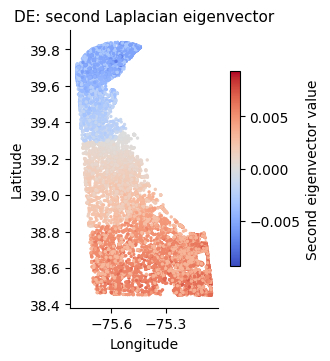

In [6]:
from src.eda import graph_laplacian_eda

laplacian_summary, laplacian_figures = graph_laplacian_eda(data)
display(laplacian_figures[0])
plt.close(laplacian_figures[0])

#### 3.1.3 Accident Distribution over Time

**Recorded accidents over time**

The figure below shows a time series plot of the recorded accidents over time for Delaware. The plots segment the periods according to the training, validation, and test sets used in the original paper from Nippani et al. (2023). As Delaware's data starts from an earlier date, the recorded accidents began much earlier in 2009. Recorded counts rose sharply between 2009 and 2010, remained relatively stable through 2012, and generally increased in subsequent years. However, it experienced a significant drop in accidents around April 2020. This coincides with the lockdown orders placed during the COVID-19 pandemic (Castillo et al., 2020). The accidents slowly recovered to their previous values after the lockdown period.

Furthermore, we also analysed the potential of any seasonality in the data. We observed that there is a consistent seasonality where the mean recorded accidents are lower at the start of the year and slowly increase from January to December. The last quarter of the year usually has a higher mean recorded accidents. This might be attributed to increased travelling due to the festive season at the end of the year.

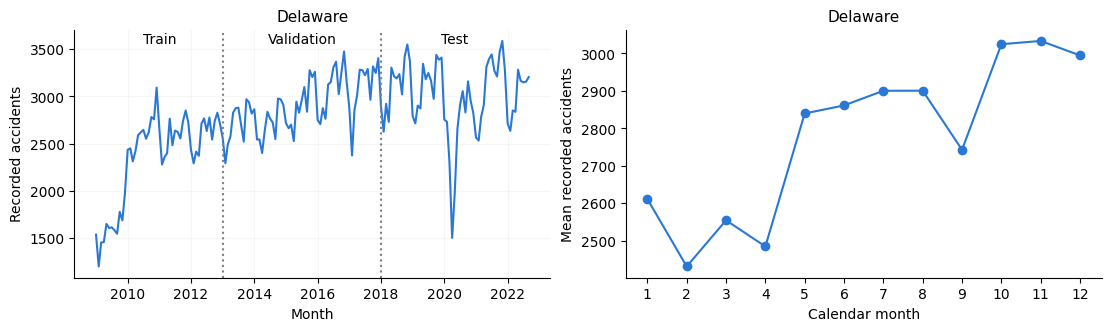

In [7]:
from src.eda import plot_monthly_accidents, plot_seasonality

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
plot_monthly_accidents(data, ax=axes[0])
plot_seasonality(data, ax=axes[1])
plt.show()


#### 3.1.4 Accident Sparsity and Concentration

Accident counts are sparse at the road-month level. In Delaware, 96.52% of roads recorded no accidents in a given month. Positive counts are therefore concentrated in a small proportion of road-months. Accidents are also unevenly distributed across roads. Over the full observation period, the 10% of roads with the highest recorded counts accounted for 70.6% of accidents in Delaware. These patterns indicate that accidents are highly sparse and concentrated in a small proportion of roads, and may suggest that prediction tasks should use evaluation metrics that account for class imbalance and assess how well models identify higher-risk roads.

,Road-months,Zero accidents (%),Mean count
State,,,
Delaware,"10,766,580",96.52,0.0426


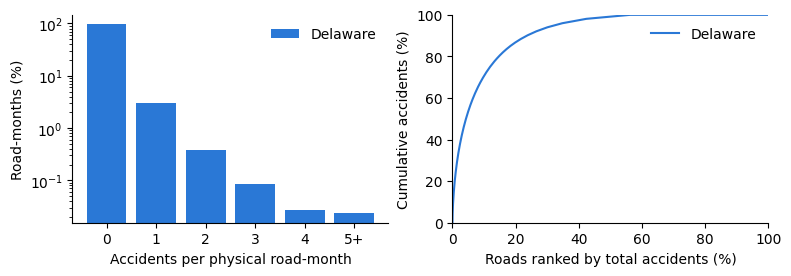

In [8]:
display(distribution[['Road-months', 'Zero accidents (%)', 'Mean count']].style.format({
    'Road-months': '{:,.0f}', 'Zero accidents (%)': '{:.2f}', 'Mean count': '{:.4f}',
}))
fig = plot_risk_profile(data)
plt.show()


#### 3.1.5 Road Characteristics and Spatial Patterns

**Road characteristics, traffic volume, and accidents**

We examined the relationships between road length, road type, AADT, and recorded accidents. For the road-length and AADT plots, observations were grouped into five quantiles for better visibility, while Spearman correlations were calculated using the ungrouped observations. Road length had a Spearman correlation of 0.258 with mean accidents per road-month. This indicates a positive relationship: longer roads tended to record more accidents per month. Longer segments also cover more distance, so they provide a greater opportunity for accidents to occur. Among the road types shown, motorways had the highest mean accident count per road-month, while residential roads had the lowest. This comparison includes roads assigned a single road type and categories containing at least 100 roads. AADT had a Spearman correlation of 0.111 with the mean monthly accident count in the same year, indicating a weak positive relationship. Roads carrying more traffic tended to record more accidents, consistent with a greater number of vehicles being exposed to accident risk. Together, these findings suggest that road length, road type and traffic volume provide useful context for understanding differences in recorded accident counts across roads.

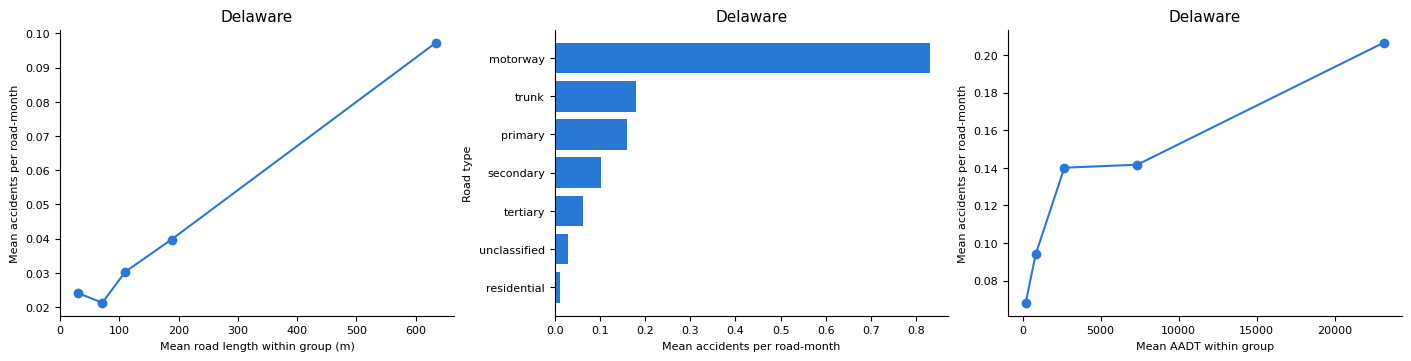

In [9]:
import numpy as np
import pandas as pd
from src.eda import (plot_length_risk, plot_road_type_risk, traffic_accident_association,
                     plot_traffic_risk, _feature_series, _risk, STATE_NAMES)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
plot_length_risk(data, training_only=False, ax=axes[0])
plot_road_type_risk(data, training_only=False, ax=axes[1])
traffic_observations = traffic_accident_association(data, training_only=False)
fig, traffic_stats = plot_traffic_risk(traffic_observations, ax=axes[2])
for ax in axes:
    ax.tick_params(labelsize=8)
    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)
plt.show()
length_stats = []
for state, state_data in data.items():
    lengths = _feature_series(state_data.edge_features['length'], state_data.n_nodes, physical=True)
    pairs = pd.DataFrame({'Length (m)': lengths.reindex(state_data.roads),
                          'Mean monthly accidents': _risk(state_data, training_only=False)}).dropna()
    pairs = pairs[pairs['Length (m)'] > 0]
    length_stats.append({'State': STATE_NAMES[state], 'Roads': len(pairs),
                         'Spearman correlation': pairs.corr(method='spearman').iloc[0, 1]})
length_summary = pd.DataFrame(length_stats).set_index('State')
traffic_summary = traffic_stats


**Road length and accident association**

| State | Roads | Spearman correlation |
| --- | ---: | ---: |
| Delaware | 65,252 | 0.258 |

**Traffic volume and same-year accident association**

| State | Observed road-years | Spearman correlation |
| --- | ---: | ---: |
| Delaware | 10,481 | 0.111 |


**Spatial exploration of recorded accidents**

We also inspect the spatial distribution of road accidents visually through an interactive map below. In Delaware, accidents are concentrated in the northern part of the state, particularly around Wilmington. Linear patterns extend southward towards central and southern Delaware, including the area around Dover. These patterns may correspond to major expressways connecting to different parts of the state. This north–south pattern also resembles the gradual change in eigenvector values observed in the graph Laplacian analysis, which reflects the connectivity of the road network. The interactive map will also show the predicted model results from the later sections. The dataset and test predictions are required before running the cell below.

In [10]:
from src.visualization.risk_map import show_risk_map
from IPython.display import FileLink, display

SHOW_INTERACTIVE_MAPS = True
MAP_MAX_ROADS = None  # Display every road in each state network.
MAP_OUTPUT_DIR = PROJECT_DIR / 'results' / 'visualizations'
if SHOW_INTERACTIVE_MAPS:
    eda_map_path = show_risk_map(
        PROJECT_DIR, max_roads=MAP_MAX_ROADS, mode='eda',
        data_dir=DATA_DIR, results_dir=PROJECT_DIR / 'results', state_codes=STATES,
        output_path=MAP_OUTPUT_DIR / 'road_safety_full_eda.html',
    )
    display(FileLink(str(eda_map_path), result_html_prefix="Open standalone map: "))


Saved standalone application: C:\Users\jasoncp\CS5284_GML\results\visualizations\road_safety_full_eda.html


C:\Users\jasoncp\CS5284_GML\results\visualizations\road_safety_full_eda.html

### 3.2 OpenStreetMap Road Context



#### 3.2.1 Data Source and Motivation

The benchmark's road inputs consist only of road-type indicators and segment length, together with annual average daily traffic (AADT), which is observed for only 3.16% of physical roads in Delaware. Its road graph was itself derived from OSM, but the descriptive attributes that OSM records for many of these roads, such as speed limits, lane counts, junction controls and nearby amenities, were not retained.

This subsection describes how these attributes were extracted, matched to the benchmark's roads, cleaned and encoded, and examines which of them are associated with accident rates independently of any model. Their effect on prediction (RQ1) is reported in Section 5.3.

The OSM data were taken from a dated extract of Delaware published by Geofabrik, a snapshot of 18 October 2026 distributed under the Open Database Licence (Geofabrik GmbH & OpenStreetMap contributors, 2026). A single dated snapshot was used rather than one extract per accident year, because processing a series of extracts was beyond the computational and storage resources available to this project; a dated file also allows the pipeline to be reproduced exactly. The consequences of this choice are discussed in Section 6.1. The extract was read with the OSMnx library (Boeing, 2025) and converted into three tables: road segments with their recorded attributes, point features that control traffic (signals, stop and give-way signs, pedestrian crossings and traffic-calming devices), and points of interest such as schools, bus stops, food outlets and parking. Before matching, the benchmark's node coordinates were corrected, because the latitude and longitude columns in the released node files are labelled the wrong way round for all 49,023 Delaware intersections, and the node order of every road was verified against its recorded length.

#### 3.2.2 Road Matching and Validation

The benchmark's road graph was built from an older version of OSM, and the map has changed since then. Only 88.8% of the benchmark's intersection identifiers still exist in the current extract, and the current network contains about 10% more intersections and roads. For each benchmark road, we therefore had to find the corresponding road in the current map.

Matching was done in two steps. First, each benchmark intersection was linked to the OSM intersection with the same identifier if the two lie within 25 m of each other, and otherwise to the nearest OSM intersection within 20 m. Second, each benchmark road was linked to an OSM road by the first of three rules that applies: an exact match, which is an OSM road with the same two end points; a reverse match, with the same end points in the opposite order; or a nearest match, which is the closest OSM road whose midpoint lies within 30 m and whose length is 0.6 to 1.6 times the benchmark length.

Linking each road to the closest candidate within a set distance is a common way of combining two maps of the same area (Goodchild & Hunter, 1997). We set the distance limits well above the usual positional error of OSM. Haklay (2010) found that roads in OSM lie on average about 6 m from their position in official survey maps, so limits of 20 to 30 m ensure that a road is not left unmatched merely because the two maps place it a few metres apart. The length condition is our own choice rather than a published value. It prevents a short side street from being matched to a long main road that runs next to it.

The table below summarises the results. Overall, 89.6% of the 116,196 directed roads were matched, and 85.1% were exact matches. We checked the matches in three ways. First, because the matching never uses road type, road type provides an independent check. The benchmark's road type agrees with that of the matched OSM road for 94.6% of exact matches and 84.6% of nearest matches, and most disagreements are between similar classes, such as primary and trunk roads. Second, exact matches have almost identical lengths in both sources, with a median length ratio of 1.00. Third, the result is not sensitive to the chosen limits. With distance limits from 10 to 75 m and length limits from 0.8–1.25 to 0.5–2, the match rate stays between 87.0% and 92.1%.

Two groups of roads are small in number but account for many accidents. Roads that could only be matched by the third rule, to the nearest OSM road within 30 m, make up 4.0% of roads but 14.9% of accidents. These are likely to be mainly major roads. OSM often draws a major road as two separate one-way roads, one for each direction, whereas the benchmark contains a single road, so the end points in the two maps differ and only the distance rule finds a match. Roads with no match at all make up 10.4% of roads but 15.7% of accidents. Removing them would discard about one in six of the accidents the model must predict, so they are kept, with an indicator telling the model that the road has no OSM information.

| Matching tier | Directed roads | Share of roads | Share of accidents | Road type agrees | Length ratio, median [5th, 95th percentile] |
|---|---|---|---|---|---|
| Exact (same end nodes) | 98,855 | 85.1% | 68.9% | 94.6% | 1.00 [0.97, 1.04] |
| Reverse (end nodes swapped) | 584 | 0.5% | 0.4% | 90.6% | 1.00 [0.87, 1.15] |
| Nearest (within 30 m, ratio 0.6–1.6) | 4,636 | 4.0% | 14.9% | 84.6% | 0.94 [0.64, 1.52] |
| Matched in total | 104,075 | 89.6% | 84.3% | | |
| Not matched | 12,121 | 10.4% | 15.7% | | |
| All benchmark roads | 116,196 | 100.0% | 100.0% | | |

*Outcome and validation of matching the benchmark's directed roads to OSM in Delaware. Road-type agreement compares the benchmark's road type with that of the matched OSM road, which the matching procedure does not use. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 8 and 9.1.*



#### 3.2.3 Attribute Availability, Cleaning and Missing Values



OSM attributes are entered by volunteers as free text, so each attribute was converted to a numerical value using fixed rules. Where several values were recorded for one road segment, the highest value was kept; for example, "25 mph; 35 mph" became 35 mph. Values recorded only in words, such as "none", were treated as missing, and a road whose OSM segments recorded different surfaces was classified as mixed.

Several attributes are missing for most roads. The speed limit is recorded for only 13.9% of roads, but those roads carry 43.8% of accidents, because major roads are mapped more thoroughly than residential streets. A missing value therefore indicates that the attribute was not mapped rather than that its value is zero, and whether a value is recorded is itself informative. Each missing value was replaced by the mean of the feature, and an indicator was added to record whether the value was recorded in OSM or filled with the mean.

We also tested whether the three most incomplete attributes, the speed limit, the number of lanes and the surface, could instead be estimated from neighbouring roads of the same road type. Only the speed limit met the acceptance criteria, and even then 88.6% of roads with a missing speed limit have no neighbour with a recorded value, so their estimate would come from road type alone, which the model already receives as an input. The estimated values were therefore not used in the model. The method and validation results are given in Appendix A.2.

#### 3.2.4 Feature Construction and Encoding

From the matched data, 58 features were constructed in five groups, which are shown in the table below with the reason for including each group. Each feature was attached to a road in one of four ways. Road attributes were taken from the matched OSM road. Control points were assigned to a road if they lie on its start or end junction, and control points between junctions were assigned to the nearest road within 15 m. Nearby places were counted within 100, 250, 500 and 1,000 m of the road's midpoint, together with the distance to the nearest place of each kind. Road shape was computed from the benchmark's own road geometry. Road type and length, which the benchmark already contains, were not duplicated. Appendix A.1 lists every feature with its definition, OSM source and encoding.

| Group | Features | Rationale | Roads with a value |
|---|---|---|---|
| Road character | speed limit, number of lanes, surface, bridge, tunnel | Speed and road width shape traffic volume and the frequency and severity of conflicts | 13–17% (speed, lanes, surface); 90% (bridge, tunnel) |
| Intersection control | signals, stop signs, give-way signs and crossings at the road's ends and between junctions; roundabouts; traffic calming | Accidents concentrate at junctions, and the form of control changes how conflicting movements are resolved | 90% |
| Cycle, pedestrian and lighting | cycle lane, sidewalk, street lighting | Indicate the presence of vulnerable road users and visibility at night | 1–2% |
| Nearby places | counts of schools, bus stops, food outlets, bars, parking, crossings and signals within 100–1,000 m, and distance to the nearest of each | Proxies for pedestrian activity, turning traffic and urban density; available for every road | 100% |
| Road shape | curvature ratio (length divided by straight-line distance) | Bends reduce sight distance | 99% |

*OSM feature groups for Delaware. Coverage is the share of the 116,196 directed roads with a value. A complete list is given in Appendix Table A1.*

The features were encoded in the same way as the benchmark's own road features. Counts and distances, which are highly skewed, were log-transformed, continuous features were standardised, and the surface was one-hot encoded. Together with the missing-value indicators described in Section 3.2.3 and an indicator for roads without an OSM match, this gives 70 encoded columns for each directed road.

#### 3.2.5 Associations with Accident Rates

Before adding the OSM features to a model, we examined whether they are associated with accident rates. Comparing raw accident counts would be misleading, because long roads and major roads have more accidents regardless of their other features (Section 3.1.5). Each road was therefore compared with similar roads. Roads were grouped by road type and length band, and the accident rate per kilometre per year was calculated for each group. A road's expected number of accidents was then its group's rate multiplied by its length and the number of years observed. For each feature, the rate ratio is the number of accidents observed on roads with that feature divided by the number expected. A ratio of 2 means twice as many accidents as on similar roads, and a ratio of 0.5 means half as many.

Features that tend to occur together can all appear risky for the same reason. A busy street, for example, typically has traffic signals, pedestrian crossings and restaurants, so all three may show high ratios even if only the busy setting is responsible. We therefore also fitted a Poisson regression, a standard model for count data, that includes all features together with road type and length. It estimates the rate ratio of each feature with the other features held fixed. The table below reports both analyses for selected features.

| Feature (level) | Rate ratio relative to similar roads [95% CI] | Roads where known | Clear in the joint regression |
|---|---|---|---|
| Food outlets within 250 m (6 or more) | 2.44 [2.28, 2.62] | 100% | Yes |
| Traffic signals within 250 m (6 or more) | 2.01 [1.90, 2.12] | 100% | Yes |
| Signal at a road end | 1.85 [1.78, 1.93] | 90% | Yes |
| Number of lanes (4 or more) | 1.70 [1.54, 1.87] | 15% | Yes |
| Stop sign at a road end | 1.68 [1.54, 1.84] | 90% | Yes |
| Stop signs between junctions (2 or more) | 0.57 [0.47, 0.70] | 90% | Yes |
| Roundabout | 0.29 [0.20, 0.41] | 90% | Yes, but weaker and not confirmed in the training years |
| Signals between junctions (2 or more) | 3.41 [1.75, 6.63] | 90% | No: 1.69 [0.90, 3.20] |
| Crossings between junctions (2 or more) | 2.63 [2.30, 3.01] | 90% | No: 1.23 [1.08, 1.40] |

*Accident rates on roads with selected OSM features relative to similar roads in Delaware, 2009–2022. The interval accounts for accidents clustering on a few roads. An effect is counted as clear only if its interval excludes 1 and the ratio lies outside 0.8–1.25. The final column reports whether the effect remains clear, in the same direction, in the joint Poisson regression, which includes road type and an exposure offset and uses robust standard errors (MacKinnon & White, 1985). Source: `notebooks/osm_features_and_eda.ipynb`, Stage 12.*

The results lead to three conclusions. First, roads in busy surroundings have markedly more accidents. Roads with many food outlets or traffic signals nearby, or with a signal or stop sign at either end, have between 1.7 and 2.4 times the accidents of similar roads, and these effects remain clear in the joint regression. Second, the two largest single-feature effects, for signals and crossings between junctions, largely disappear in the joint regression, which suggests that these features mark busy areas rather than adding risk of their own. Third, roundabouts and repeated stop signs between junctions are associated with fewer accidents, consistent with their role in slowing traffic. The same patterns are observed when the analysis is restricted to the training years, 2009–2012.

These results identify features that are associated with higher or lower accident rates; they do not establish that the features cause accidents. A road with many restaurants nearby, for example, is likely to have more accidents because it carries heavy traffic rather than because of the restaurants themselves. For prediction, however, this distinction is not essential: a feature that reliably identifies high-accident roads is useful to the model regardless of the underlying cause, which motivates the inclusion of the OSM features in the model.

### 3.3 Engineered Accident-History Features



#### 3.3.1 Motivation

Road type, length and network position describe relatively stable properties of a road. Weather and traffic provide time-varying context, but these inputs do not capture the sequence of crashes on a road in the months leading up to a forecast. We therefore summarise monthly crash records on each road and its neighbours to test whether this history improves forecasts of next-month crash occurrence and count.


#### 3.3.2 Feature Construction

For a prediction in month $t$, only earlier months enter the ten raw features. These fall into three groups.

**1. Own-road history (six features).** The previous month's count $c_{r,t-1}$ captures recent activity. The count twelve months earlier, $c_{r,t-12}$, provides a comparison with the same calendar month of the previous year. Three rolling means describe how the recent monthly crash count compares across a quarter, half a year and a full year. The sixth feature measures how regularly crashes recur over the year.

$$\mathrm{Mean}_{k}(r,t)=\frac{c_{r,t-1}+\cdots+c_{r,t-k}}{k},\qquad k\in\{3,6,12\}.$$

$$\mathrm{Recurrence}_{12}(r,t)=\frac{\text{number of months with at least one crash in the preceding 12 months}}{12}.$$

The annual mean gives equal weight to every crash. Recurrence counts each crash-positive month once, so it distinguishes crashes concentrated in one month from the same total spread across the year. Each lag requires its source month to be available, and each rolling measure requires its full window.

**2. Neighbouring-road history (three features).** Roads sharing either endpoint with the target road provide local context when the road itself has little recent history. We count each distinct neighbouring road once and exclude the target road. For roads with at least one neighbour, we compute

$$\mathrm{NeighbourMean}(x)=\frac{\text{sum of }x\text{ across neighbouring roads}}{\text{number of neighbouring roads}}.$$

Applying this average first to each neighbour's previous-month count and then to its three-month rolling mean gives two features. Averaging makes the scale interpretable as crashes per neighbouring road. The third feature, the number of neighbours, distinguishes an isolated road from a connected road whose neighbours recorded no crashes. Both have zero neighbour averages when the source window is available. An unavailable window is recorded as missing.

**3. Source coverage (one feature).** We count how many of the preceding twelve months have usable source records. A month with usable records counts towards coverage even when the road recorded zero crashes. This distinguishes a fully observed quiet year from a year with incomplete records.



The table summarises the ten constructed history features, their definitions and the reason for including each.


In [11]:
from src.history.report import history_feature_catalog

display(history_feature_catalog())

,Feature,Definition,Reason for inclusion
0,acc_lag_1m,Own-road count at T−1,Immediate persistence
1,acc_mean_3m,Own-road mean over T−3…T−1,Smooth recent noise
2,acc_mean_6m,Own-road mean over T−6…T−1,Medium-term baseline
3,acc_mean_12m,Own-road mean over T−12…T−1,Annual-scale baseline
4,acc_lag_12m,Own-road count at T−12,Same-season reference
5,acc_nonzero_fraction_12m,Share of prior 12 months with count > 0,Recurring vs isolated risk
6,neighbor_acc_lag_1m_mean,Adjacent-road mean at T−1,Recent local context
7,neighbor_acc_mean_3m,Adjacent-road mean over T−3…T−1,Smoothed local context
8,neighbor_count,Distinct physical roads sharing an endpoint,Neighbourhood support
9,history_months_available_12m,Usable source months in prior year,Coverage context


#### 3.3.3 Exploratory Data Analysis

We examined feature availability and distribution over the 48 model-training months from 2009–2012, covering 65,252 physical-road proxies. The first two panels show the share of available road-months with zero history and the positive-value distributions for own-road and neighbour three-month means. The third panel shows Spearman correlations among four own-road history measures, calculated from a fixed random sample of 100,000 eligible training road-months. Outcome associations are evaluated only on 2010–2012 targets after a twelve-month history warm-up, so validation and test labels do not inform these exploratory results.



##### Distribution of Accident-History Features

The left panel shows that crash history is sparse. Only 7.3% of observed own-road three-month means are positive, compared with 24.1% for the neighbour mean. Even for the twelve-month own-road mean, 81.4% of observed values are zero. The middle panel shows that positive neighbour means span a broader range, providing local context that can distinguish some roads whose own recent history is zero.

The right panel shows substantial overlap among the own-road windows. The six- and twelve-month means have a Spearman correlation of 0.818, while the twelve-month mean and recurrence measure are perfectly correlated at the displayed precision. These patterns suggest that the history inputs contain both complementary local context and overlapping summaries of past crashes. As a result, the later model comparison evaluates the history features as a group and does not isolate the contribution of each individual window.


Source coverage: 166 months have rows; 165 are usable through 2022-09 under the current cutoff.
2022-10 recorded count: 23; 2022-11/12 have rows: False.
Training direction audit: 50,944 two-way pairs; 15,057 with crashes, 15,057 with records on one orientation only.
No two-way positive road-month has crashes on both orientations (0/49,329); 96.65% of two-way counts are on lower-index-to-higher-index edges.


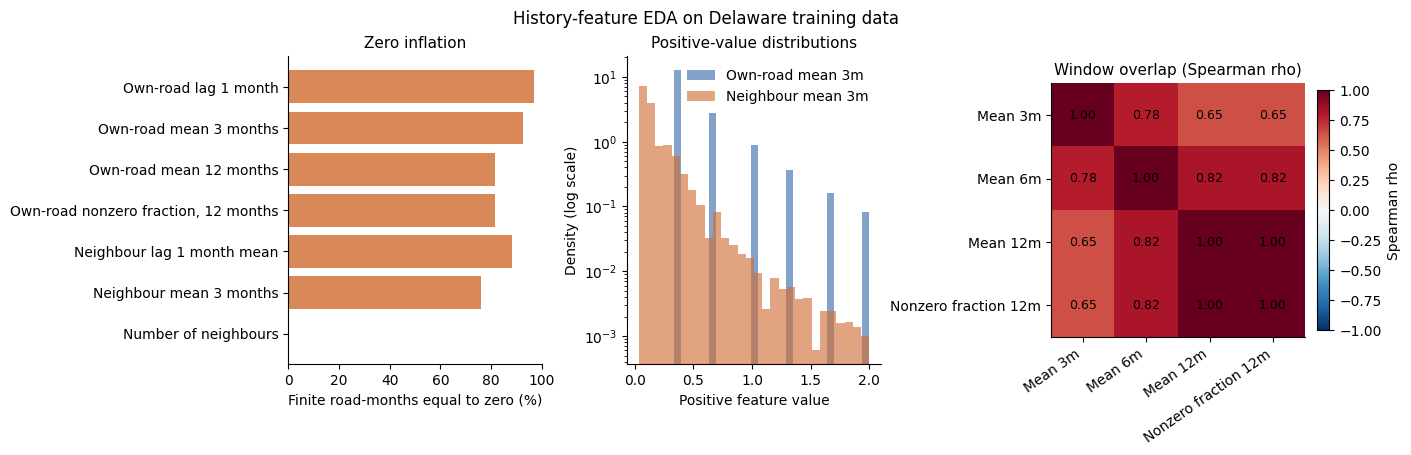

In [12]:
import numpy as np
from src.data.history import build_physical_features
from src.history.report import (
    load_training_road_counts, history_feature_profile,
    history_window_correlations, plot_history_profile,
)

counts, usable_months, neighbours, edge_to_road = load_training_road_counts(DATA_DIR / "DE")
train_features = np.stack([
    build_physical_features(counts, usable_months, month, neighbours)
    for month in range(len(counts))
])
profile = history_feature_profile(train_features)
correlation = history_window_correlations(train_features)
plot_history_profile(train_features, profile, correlation)
plt.show()

##### Relationship Between Accident History and Future Accidents
Using Delaware training targets from 2010–2012, after a twelve-month history warm-up, we examined whether past accidents were associated with subsequent accident occurrence. We grouped road-months by whether the road had recorded an accident in the preceding one, three, six or twelve months, then calculated the proportion with an accident in the current month. This proportion was 21.81% for roads with an accident in the previous month, compared with 2.44% for those without one. The same pattern held across longer windows, consistent with Briz-Redón et al. (2022).

Both next-month accident incidence and mean crash count also increased with the number of crashes in the preceding quarter. Comparing roads with no crashes against those with six or more, incidence rose from 2.04% to 75.80%, while the mean count rose from 0.0221 to 2.1551. However, the latter group contained only 2,657 road-months, compared with more than 2.16 million in the crash-free group.

Among roads with a crash-free quarter, next-month incidence was 1.15% when their neighbours also had no recent crashes and 5.17% when at least one neighbour had a recent crash. Neighbour history therefore distinguishes roads with otherwise identical zero own-road history. Together, these training-period associations motivate evaluating own-road and neighbour history as predictive features on held-out months.

In [13]:
from src.eda import history_window_risk
history_windows = history_window_risk(data)
display(history_windows.style.format({'Road-months': '{:,.0f}', 'Accident road-months': '{:,.0f}',
                                     'Next-month accident (%)': '{:.2f}'}))

,State,Prior months,History,Road-months,Accident road-months,Next-month accident (%)
0,Delaware,1,None,"2,975,238","72,470",2.44
1,Delaware,1,One or more,"91,606","19,981",21.81
2,Delaware,3,None,"2,721,525","51,794",1.90
3,Delaware,3,One or more,"214,815","38,333",17.84
4,Delaware,6,None,"2,411,285","36,357",1.51
5,Delaware,6,One or more,"329,299","49,749",15.11
6,Delaware,12,None,"1,911,333","21,990",1.15
7,Delaware,12,One or more,"437,739","55,553",12.69


,Prior 3-month accidents,Road-months,Next-month incidence (%),Mean next-month count
0,0,2163898,2.0446,0.0221
1,1,136650,12.5196,0.1475
2,2,30091,24.9809,0.3232
3,3–5,15776,42.2287,0.6418
4,6+,2657,75.7998,2.1551


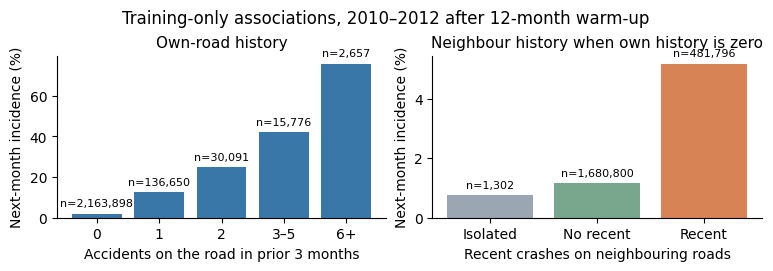

In [14]:
from src.history.report import history_association_tables, plot_history_associations

own_risk, neighbour_risk = history_association_tables(counts, neighbours)
display(own_risk.round(4))
figure = plot_history_associations(own_risk, neighbour_risk)
plt.show()

#### 3.3.4 Feature Preprocessing

The ten raw history features are standardised using means and standard deviations fitted on training months only. For a missing value, the transformation returns zero, equivalent to filling it with the training mean before standardisation. Eight binary indicators retain missingness for the six own-road and two neighbour-history measures; neighbour count and source coverage are always defined. The result is an 18-column history vector for each physical road.


In [15]:
from src.data.history import HistoryScaler

scaler = HistoryScaler().fit(train_features)
road_history = scaler.transform(train_features[36], "all")
edge_history = road_history[edge_to_road]
print("January 2012 physical-road history:", road_history.shape)
print("Directed-edge history:", edge_history.shape)

January 2012 physical-road history: (65252, 18)
Directed-edge history: (116196, 18)


## 4. Methodology

### 4.1 Prediction Tasks and Shared Setup

We implemented Node2Vec-style embeddings and all four predictors in PyTorch, using the shared protocol below.


#### 4.1.1 Task Formulation and Prediction Framework

For physical-road proxy $r$ and month $t$, classification predicts $\mathbb{1}(y_{r,t}>0)$ and regression predicts count $y_{r,t}$, including zeros. Counts are summed across directed edges sharing unordered endpoints; message passing retains the directed graph (Section 3.1.1). Tasks are trained separately. Every model concatenates endpoint representations and road attributes:

$$s_{r,t}=f_\theta([h_u\,\|\,h_v\,\|\,e_{r,t}]).$$

Graph encoders learn $h_u,h_v$; MLP uses endpoint inputs directly. Classification applies a sigmoid; negative regression outputs are clipped to zero at evaluation.


#### 4.1.2 Training Procedure

The chronological splits are January 2009–December 2012 for training (48 months), January 2013–December 2017 for validation (60), and January 2018–September 2022 for testing (57), on the same network. Incomplete final months are excluded (Section 3).

Each configuration uses seeds 0/1/2, 100 epochs, Adam (learning rate 0.001; Kingma & Ba, 2014) and zero dropout. Months are shuffled; within each, all accident-positive roads and an equal number of zero-count roads sampled without replacement are retained, subject to availability. Training skips months with fewer than ten positives. Classification minimises binary cross-entropy with logits; regression minimises MAE on raw outputs. Validation and testing use all physical-road proxies.


#### 4.1.3 Evaluation and Checkpoint Selection

Validation runs every five epochs and at epoch 100. Each seed's checkpoint maximises full-network validation AUROC for classification or minimises validation MAE for regression; testing follows selection. All runs complete 100 epochs.

Monthly AUROC is weighted by accident-positive road counts, excluding single-class months. AP uses scikit-learn's average-precision definition over pooled test road-months. Top-1% precision and recall select each month's highest-scoring 1% of roads, rounding upwards, then average equally across months; recall excludes months without positives. Count MAE averages all test road-months; subgroup AUROC pools observations within each subgroup. We report means and population standard deviations across three seed checkpoints.


### 4.2 Input Features

The main comparisons retain baseline inputs and one fixed Node2Vec embedding; OSM and history augment road attributes.


#### 4.2.1 Baseline Inputs

Node inputs are coordinates, degree, approximate betweenness, monthly weather and weather-missingness indicators. Road inputs are road type, length, available traffic volume and its missingness indicator. Weather and traffic use training-period standardisation, zero filling after scaling and missingness flags (Section 3.1).


#### 4.2.2 Node2Vec Structural Embeddings

Our GPU implementation learns skip-gram embeddings with negative sampling (Grover & Leskovec, 2016; Mikolov et al., 2013), replacing the benchmark backend. Settings are: 128 dimensions; ten 20-node walks per node; forward context window five; one negative per positive pair; one epoch; Adam learning rate 0.01; starting-node batch size 1,024; seed 0. Walks use the undirected, deduplicated network with $p=q=1$ (unbiased walks).

Standardised embeddings are concatenated with node inputs, frozen and reused across architectures, input settings and model seeds. Thus, MLP receives topology information without message passing. Embeddings use no accident labels, but access to the full known topology makes evaluation transductive. Seed deviations exclude embedding-generation uncertainty. Section 5.3.2 additionally examines GraphSAGE without Node2Vec.


#### 4.2.3 OpenStreetMap Features

The 58 OSM features yield 70 encoded road columns (Section 3.2), fixed across months. They enter every model's prediction head and, for graph models, the messages, gates or attention described below. Controls omit these columns; the pipeline is illustrated below.


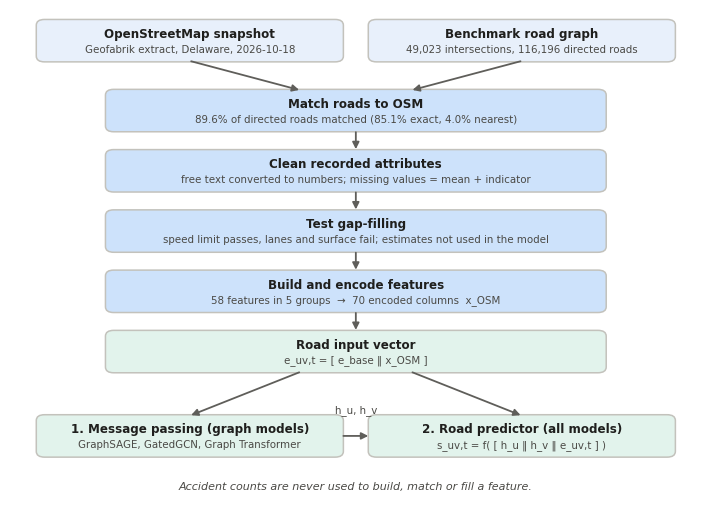

In [16]:
from src.osm.report import load_osm_results, permutation_table, plot_osm_pipeline

fig = plot_osm_pipeline()
plt.show()

*OSM pipeline: match benchmark roads, clean and encode attributes, then append them to road inputs. Feature construction uses no accident counts.*


#### 4.2.4 Accident-History Features

History features are constructed for each undirected physical road and appended to the static road inputs used by the model. Because message passing operates on directed edges, each physical-road history vector is copied to both edge directions before concatenation. All models use the combined road inputs in the per-road prediction head; graph models also use them to form messages. Baseline controls omit history, while combined-feature runs include both OSM and accident history.


### 4.3 Model Architectures

MLP and edge-aware GraphSAGE are the selected reproduction baselines; GatedGCN and Graph Transformer extend the original paper's evaluated model set. All use a road predictor with a 256-unit ReLU hidden layer and scalar output. Graph encoders have two layers/blocks of width 256, implemented with native PyTorch operations. Parameter counts and internal transformations differ, so comparisons evaluate complete architectures.


#### 4.3.1 MLP

Endpoint inputs and road attributes enter the shared prediction-head design directly, providing a control without learned message passing.


#### 4.3.2 GraphSAGE

Following the benchmark adaptation (Hamilton et al., 2017; Nippani et al., 2023), each incoming message adds linear transformations of the source representation and connecting-road attributes. Messages and a transformed self contribution are averaged, L2-normalised and batch-normalised, with ReLU between layers. All incoming neighbours are used with uniform aggregation weights; road attributes affect message contents.


#### 4.3.3 Gated Graph Convolutional Network (GatedGCN)

Node and road inputs are projected to width 256 (Bresson & Laurent, 2017). Edge updates combine current edge and endpoint states; sigmoid gates weight neighbour messages feature-wise, normalised by incoming gate sums, alongside a self transformation. Node and edge updates use batch normalisation, ReLU and residual addition. Edge states evolve across layers. No self-loops are added; final node states and original road attributes enter the predictor.


#### 4.3.4 Graph Transformer

Sparse edge-aware attention follows Dwivedi and Bresson (2020) and Vaswani et al. (2017). Each block has four 64-dimensional heads. Incoming-edge scores multiply destination queries, source keys and projected road features element-wise, then take a scaled sum. Neighbour softmax weights aggregate source values. Blocks use pre-layer normalisation, residual connections and a 512-unit GELU feedforward layer. Edge projections are block-specific; hidden edge states do not evolve. Attention uses existing directed edges without added self-loops or Laplacian positional encodings. Final node states and original road attributes enter the predictor; history supplies summaries, not temporal attention.


### 4.4 Experimental Comparisons

Four architectures × four input settings (baseline, +OSM, +history, +both) × two separately trained tasks × three seeds give 96 runs, excluding supplementary analyses. Feature comparisons hold architecture fixed; architecture comparisons hold inputs fixed. A separate seed-controlled sampler matches negatives in paired feature runs independently of model initialisation. Shared settings follow Sections 4.1–4.3.


#### 4.4.1 Baseline: All Four Architectures


Baseline-input runs provide each architecture's feature-comparison reference and assess message passing beyond supplied Node2Vec structure.


#### 4.4.2 Adding OSM

RQ1 compares baseline and +OSM within each architecture and task. Supplementary GraphSAGE classification repeats this comparison without Node2Vec. Grouped permutation importance shuffles one OSM group across test roads and measures the AUROC drop, with three repetitions per seed (Fisher et al., 2019). No retraining occurs: this measures fitted-model reliance, not standalone or causal contributions.


#### 4.4.3 Adding Accident History: All Four Architectures

RQ2 compares +history against each model's archived baseline control across both tasks, keeping Node2Vec and training/evaluation settings fixed. History-minus-control differences use unrounded scores; higher ranking metrics and lower MAE indicate improvement.

#### 4.4.4 Combined Inputs: All Four Architectures

RQ3 compares architectures within every input configuration, emphasising combined inputs. Comparing +both against either addition alone tests incremental predictive value. These comparisons do not isolate causal mechanisms of gating, attention or feature interactions.


## 5. Results and Discussion


### 5.1 Overall Performance Summary

Table 5.1 summarises Delaware test performance for all four architectures with baseline inputs, OSM added, history added and both additions combined. All settings retain fixed Node2Vec embeddings. Entries show mean and population standard deviation over three model seeds at validation-selected checkpoints. Classification metrics and count MAE come from separately trained models; higher classification scores and lower MAE are better.


In [17]:
import json
import numpy as np
import pandas as pd

# Explicit sources avoid mixing duplicate history exports or selecting by test score.
# Baseline rows use their named no-history exports. History-only rows use
# results/history_100_epochs/v1_DE_*; alternative history exports are excluded.
# Combined rows use results/DE_*_osm_all_hist_all; OSM-only rows use results/osm/
# (MLP and GraphSAGE from the OSM notebook, GatedGCN and Graph Transformer from the
# main training script, hence the *_hist_none names). Exact paths are retained in
# architecture_summary_sources, preserving provenance across separate exports.
summary_models = [
    ("MLP", "mlp", "DE_mlp_{task}_n2v", "osm/DE_mlp_{task}_n2v_osm_all"),
    ("GraphSAGE", "graphsage", "DE_graphsage_{task}_n2v", "osm/DE_graphsage_{task}_n2v_osm_all"),
    ("GatedGCN", "gatedgcn", "DE_gatedgcn_{task}_n2v_hist_none", "osm/DE_gatedgcn_{task}_n2v_osm_all_hist_none"),
    ("Graph Transformer", "graph_transformer", "DE_graph_transformer_{task}_n2v_hist_none",
     "osm/DE_graph_transformer_{task}_n2v_osm_all_hist_none"),
]
summary_settings = ("Baseline", "Baseline + OSM", "Baseline + history", "Baseline + OSM + history")
summary_rows, summary_sources = [], []
for setting in summary_settings:
    for label, model, baseline_template, osm_template in summary_models:
        row = {"Inputs": setting, "Model": label}
        for task in ("classification", "regression"):
            if setting == "Baseline":
                relative = baseline_template.format(task=task)
            elif setting == "Baseline + OSM":
                relative = osm_template.format(task=task)
            elif setting == "Baseline + history":
                relative = f"history_100_epochs/v1_DE_{model}_{task}_n2v_hist_all"
            else:
                relative = f"DE_{model}_{task}_n2v_osm_all_hist_all"
            selected = (
                [("AUROC", "AUROC"), ("AP", "PR-AUC"),
                 ("Top-1% precision", "precision@top1%"), ("Top-1% recall", "recall@top1%")]
                if task == "classification" else [("Count MAE", "MAE")]
            )
            if relative is None:
                for column, _ in selected:
                    row[column] = "Pending incorporation"
                summary_sources.append({"Inputs": setting, "Model": label, "Task": task, "Source": "Pending incorporation"})
                continue
            path = PROJECT_DIR / "results" / relative / "metrics.json"
            payload = json.loads(path.read_text(encoding="utf-8"))
            cfg = payload["config"]
            assert payload.get("complete") and not payload.get("smoke_only"), path
            assert cfg["state"] == "DE" and cfg["model"] == model and cfg["task"] == task, path
            assert cfg["use_node2vec"] and cfg["epochs"] == 100, path
            runs = payload["runs"]
            assert sorted(run["seed"] for run in runs) == [0, 1, 2], path
            if "history" in setting:
                assert cfg.get("history_mode") == "all", path
            else:
                assert cfg.get("history_mode") in (None, "none") and not cfg.get("history_groups"), path
            if setting == "Baseline + OSM + history":
                assert cfg.get("osm_groups"), path
            for column, key in selected:
                # Match the report's population-SD convention using saved per-seed scores.
                values = np.array([run["test"]["all"][key] for run in runs], dtype=float)
                assert np.isfinite(values).all(), (path, key)
                row[column] = f"{values.mean():.4f} \u00b1 {values.std(ddof=0):.4f}"
            summary_sources.append({"Inputs": setting, "Model": label, "Task": task, "Source": str(path.relative_to(PROJECT_DIR))})
        summary_rows.append(row)

architecture_summary = pd.DataFrame(summary_rows).set_index(["Inputs", "Model"])
architecture_summary.columns = pd.MultiIndex.from_tuples([
    ("Classification", "AUROC"),
    ("Classification", "AP"),
    ("Classification", "Top-1% precision"),
    ("Classification", "Top-1% recall"),
    ("Regression", "Count MAE"),
])
architecture_summary_sources = pd.DataFrame(summary_sources)


**Table 5.1. Delaware test performance with fixed Node2Vec: mean and population SD over seeds 0, 1 and 2. AUROC, AP and top-1% precision and recall come from the classification models and count MAE from the regression models. Higher classification scores are better; lower count MAE is better.**

| Inputs | Model | AUROC | AP | Top-1% precision | Top-1% recall | Count MAE |
| --- | --- | --- | --- | --- | --- | --- |
| Baseline | MLP | 0.8780 ± 0.0002 | 0.2788 ± 0.0016 | 0.4822 ± 0.0022 | 0.1289 ± 0.0005 | 0.2201 ± 0.0040 |
| Baseline | GraphSAGE | 0.8743 ± 0.0003 | 0.2627 ± 0.0013 | 0.4585 ± 0.0031 | 0.1226 ± 0.0009 | 0.2070 ± 0.0038 |
| Baseline | GatedGCN | 0.8747 ± 0.0010 | 0.2714 ± 0.0031 | 0.4732 ± 0.0060 | 0.1267 ± 0.0015 | 0.1812 ± 0.0035 |
| Baseline | Graph Transformer | 0.8734 ± 0.0004 | 0.2693 ± 0.0015 | 0.4671 ± 0.0028 | 0.1249 ± 0.0008 | 0.1882 ± 0.0032 |
| Baseline + OSM | MLP | 0.8807 ± 0.0001 | 0.2822 ± 0.0030 | 0.4872 ± 0.0054 | 0.1303 ± 0.0014 | 0.2122 ± 0.0057 |
| Baseline + OSM | GraphSAGE | 0.8772 ± 0.0008 | 0.2740 ± 0.0017 | 0.4714 ± 0.0015 | 0.1261 ± 0.0003 | 0.2016 ± 0.0007 |
| Baseline + OSM | GatedGCN | 0.8771 ± 0.0008 | 0.2756 ± 0.0016 | 0.4793 ± 0.0052 | 0.1282 ± 0.0014 | 0.1764 ± 0.0031 |
| Baseline + OSM | Graph Transformer | 0.8756 ± 0.0009 | 0.2719 ± 0.0048 | 0.4652 ± 0.0137 | 0.1244 ± 0.0036 | 0.1767 ± 0.0039 |
| Baseline + history | MLP | 0.8858 ± 0.0005 | 0.3172 ± 0.0011 | 0.5413 ± 0.0013 | 0.1448 ± 0.0004 | 0.2199 ± 0.0052 |
| Baseline + history | GraphSAGE | 0.8860 ± 0.0002 | 0.3250 ± 0.0009 | 0.5568 ± 0.0021 | 0.1489 ± 0.0006 | 0.2107 ± 0.0133 |
| Baseline + history | GatedGCN | 0.8848 ± 0.0002 | 0.3214 ± 0.0020 | 0.5513 ± 0.0027 | 0.1474 ± 0.0007 | 0.1891 ± 0.0112 |
| Baseline + history | Graph Transformer | 0.8837 ± 0.0003 | 0.3183 ± 0.0019 | 0.5441 ± 0.0024 | 0.1455 ± 0.0006 | 0.1530 ± 0.0020 |
| Baseline + OSM + history | MLP | 0.8878 ± 0.0000 | 0.3199 ± 0.0016 | 0.5421 ± 0.0028 | 0.1450 ± 0.0008 | 0.2235 ± 0.0081 |
| Baseline + OSM + history | GraphSAGE | 0.8877 ± 0.0005 | 0.3261 ± 0.0008 | 0.5579 ± 0.0004 | 0.1492 ± 0.0001 | 0.1999 ± 0.0063 |
| Baseline + OSM + history | GatedGCN | 0.8868 ± 0.0004 | 0.3243 ± 0.0003 | 0.5538 ± 0.0023 | 0.1481 ± 0.0006 | 0.1764 ± 0.0044 |
| Baseline + OSM + history | Graph Transformer | 0.8856 ± 0.0006 | 0.3203 ± 0.0014 | 0.5472 ± 0.0018 | 0.1463 ± 0.0005 | 0.1564 ± 0.0016 |


### 5.2 Baseline Performance: All Four Architectures


MLP and GraphSAGE are the two baselines selected from the original paper for modified reproduction; GatedGCN and Graph Transformer extend our comparison with two architectures not evaluated in the original paper. All four have baseline-input results in Table 5.1.

With baseline inputs and fixed Node2Vec embeddings, MLP achieves higher mean classification AUROC than GraphSAGE (0.8780 versus 0.8743). The same ordering holds for AP (0.2788 versus 0.2627) and top-1% precision (48.22% versus 45.85%). Thus, MLP's stronger occurrence ranking also translates into a more productive shortlist of high-risk roads.

For count regression, GraphSAGE has lower mean MAE (0.2070 versus 0.2201). GatedGCN and Graph Transformer achieve baseline AUROCs of 0.8747 and 0.8734, respectively, also below MLP, but have lower count MAEs of 0.1812 and 0.1882. MLP therefore leads all four baseline-input classifiers on AUROC, AP and top-1% precision and recall, while GatedGCN has the lowest count MAE. Learned message passing has a task-dependent benefit in this baseline setting. Because all four models already receive Node2Vec, this comparison assesses the additional value of learned message passing beyond the supplied structural features.



### 5.3 RQ1: Effect of OSM Features

Adding the OSM features improves all four architectures (Table 5.1). Test AUROC rises by 0.002 to 0.003 for every architecture, with all three seeds improving, and count MAE falls by 3 to 6%. The other classification metrics mostly improve as well, although less consistently across seeds for GatedGCN and the Graph Transformer. The MLP, which does not pass messages between roads, gains as much as the graph models, which suggests that the features help mainly as information about the road being scored rather than through message passing. The remainder of this section examines the GraphSAGE classifier in more detail: which feature groups it relies on, whether the gain holds over time and across road types, and why the gain is small once Node2Vec embeddings are included.


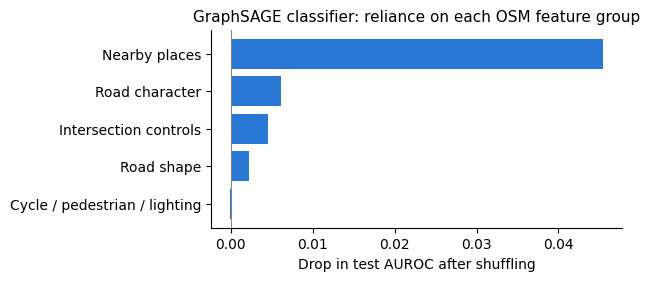

In [18]:
osm_results = load_osm_results(PROJECT_DIR)
groups = ['Nearby places', 'Road character', 'Intersection controls', 'Road shape',
          'Cycle / pedestrian / lighting']
drops = permutation_table(osm_results).loc[groups, 'With Node2Vec']

fig, ax = plt.subplots(figsize=(6.2, 2.7), constrained_layout=True)
ax.barh(groups, drops)
ax.invert_yaxis()
ax.axvline(0, color='grey', linewidth=0.7)
ax.set(xlabel='Drop in test AUROC after shuffling', title='GraphSAGE classifier: reliance on each OSM feature group')
plt.show()

*Drop in test AUROC when each OSM feature group is shuffled across test roads, for the GraphSAGE classifier with Node2Vec; mean over three repetitions for each of three seeds.*

#### 5.3.1 Feature Groups and Consistency of the Gain

The figure above shows how much the trained GraphSAGE classifier relies on each OSM feature group. Shuffling the nearby-place features reduces test AUROC by 0.045, more than half of the drop caused by shuffling all OSM features together (0.079). Every other group causes a drop of less than 0.007, and the cycle, pedestrian and lighting group has no measurable effect. This ranking follows coverage: nearby places are available for every road, whereas attributes such as speed limits, lanes and lighting are recorded for only a minority of roads. Nearby-place counts may also partly stand in for traffic volume, which is recorded for only 3% of roads.

The gain is also consistent over time and across road types. Monthly AUROC is higher with the OSM features in all 57 test months, with a mean increase of 0.0029. The gain is larger on motorways (0.014 across 706 roads) than on residential roads (0.003 across 44,294 roads), which is consistent with the more complete mapping of major roads, although the two road types also differ in accident frequency. These two analyses use the saved predictions of each model and are reported in `notebooks/osm_baseline_comparison.ipynb` (Sections 10 and 11).


#### 5.3.2 Why the Gain Is Small with Node2Vec

All comparisons above include Node2Vec embeddings. To test whether the OSM features and Node2Vec carry overlapping information, the GraphSAGE classifier was also trained with and without the OSM features after removing Node2Vec. The table below shows the four combinations.

| Test AUROC (mean ± SD, 3 seeds) | No OSM | With OSM | Change |
|---|---|---|---|
| Without Node2Vec | 0.8461 ± 0.0037 | 0.8713 ± 0.0008 | +0.0252 |
| With Node2Vec | 0.8743 ± 0.0003 | 0.8772 ± 0.0008 | +0.0029 |

*GraphSAGE classification in Delaware with and without OSM features and Node2Vec embeddings. The control without Node2Vec is the team's committed baseline run. Source: `notebooks/osm_baseline_comparison.ipynb`, Section 8.1.*

Without Node2Vec, the OSM features improve AUROC almost nine times as much as with it, and precision among the 1% of roads ranked as most at risk rises from 0.392 to 0.445. The two inputs therefore largely overlap: each improves AUROC by a similar amount on its own, but adding both gives only slightly more than adding either one. The model also relies less on the nearby-place features when Node2Vec is present.

To understand this overlap, we examined whether Node2Vec already encodes how built-up a road's surroundings are. For each road, we counted the places recorded in OSM within 1 km and fitted a model to predict this count from the road's Node2Vec embedding (`notebooks/osm_node2vec_density_check.ipynb`). The model was tested in two ways. When the test roads lay in parts of the state not used for fitting, it could not predict the count (R² of 0.06). When the test roads were chosen at random, so that neighbouring roads had been used for fitting, it predicted the count well (R² of 0.68). This shows that Node2Vec does not encode how built-up an area is; instead, nearby roads receive similar embeddings, so Node2Vec indicates where a road is located. Because the same roads are used for training and testing, knowing where a road is located already tells the model much about its accident risk, which leaves little for the OSM features to add.


### 5.4 RQ2: Effect of Accident History

Adding the 18 history inputs improved classification ranking for all four architectures. For count regression, the models also became better at identifying crash-positive roads near the top of the ranking, but their count errors changed in different directions. The tables below compare each model with its no-history Node2Vec baseline on the same Delaware test months. Entries show mean ± population standard deviation over three seeds, followed by the full-history minus baseline difference calculated before rounding.

In [19]:
from src.history.report import load_history_results, history_comparison_table

full_history_root = PROJECT_DIR / "results" / "history_100_epochs"
history_results = load_history_results(PROJECT_DIR / "results", full_history_root)
for task in ("classification", "regression"):
    print("Classification" if task == "classification" else "Count regression")
    table = history_comparison_table(history_results, task)
    display(table)

Classification


,Model,AUROC,AP,Precision@top1%
0,MLP,0.8780 ± 0.0002 → 0.8858 ± 0.0005 (+0.0077),0.2788 ± 0.0016 → 0.3172 ± 0.0011 (+0.0384),0.4822 ± 0.0022 → 0.5413 ± 0.0013 (+0.0591)
1,GraphSAGE,0.8743 ± 0.0003 → 0.8860 ± 0.0002 (+0.0117),0.2627 ± 0.0013 → 0.3250 ± 0.0009 (+0.0623),0.4585 ± 0.0031 → 0.5568 ± 0.0021 (+0.0983)
2,GatedGCN,0.8747 ± 0.0010 → 0.8848 ± 0.0002 (+0.0100),0.2714 ± 0.0031 → 0.3214 ± 0.0020 (+0.0500),0.4732 ± 0.0060 → 0.5513 ± 0.0027 (+0.0780)
3,Graph Transformer,0.8734 ± 0.0004 → 0.8837 ± 0.0003 (+0.0104),0.2693 ± 0.0015 → 0.3183 ± 0.0019 (+0.0490),0.4671 ± 0.0028 → 0.5441 ± 0.0024 (+0.0770)


Count regression


,Model,AUROC,AP,MAE,Precision@top1%
0,MLP,0.8648 ± 0.0011 → 0.8732 ± 0.0008 (+0.0084),0.2372 ± 0.0029 → 0.2674 ± 0.0071 (+0.0302),0.2201 ± 0.0040 → 0.2199 ± 0.0052 (-0.0001),0.3651 ± 0.0097 → 0.4369 ± 0.0144 (+0.0718)
1,GraphSAGE,0.8569 ± 0.0025 → 0.8580 ± 0.0045 (+0.0011),0.2196 ± 0.0034 → 0.2550 ± 0.0086 (+0.0354),0.2070 ± 0.0038 → 0.2107 ± 0.0133 (+0.0037),0.3179 ± 0.0116 → 0.4002 ± 0.0353 (+0.0823)
2,GatedGCN,0.8385 ± 0.0043 → 0.8463 ± 0.0017 (+0.0078),0.2157 ± 0.0018 → 0.2294 ± 0.0049 (+0.0137),0.1812 ± 0.0035 → 0.1891 ± 0.0112 (+0.0079),0.3414 ± 0.0059 → 0.3946 ± 0.0103 (+0.0532)
3,Graph Transformer,0.8232 ± 0.0093 → 0.8079 ± 0.0057 (-0.0153),0.1977 ± 0.0093 → 0.2046 ± 0.0059 (+0.0069),0.1882 ± 0.0032 → 0.1530 ± 0.0020 (-0.0352),0.3066 ± 0.0131 → 0.3697 ± 0.0078 (+0.0631)


#### 5.4.1 Model gains across the two tasks

The classification gains extend across models with and without learned message passing. GraphSAGE shows the largest increase in average precision and top-1% precision, but its final AUROC is nearly tied with MLP. Since MLP receives the same road-level history inputs without graph aggregation, these results suggest that the engineered history summaries carry useful local risk information directly; message passing is not required to obtain a classification benefit. The similar AUROC gains for GatedGCN and Graph Transformer show that the ranking improvement is also present with different graph encoders.

The regression results depend more strongly on which roads contribute to the error metric. Graph Transformer has the clearest overall MAE reduction, but its MAE on zero-crash road-months falls from 0.1773 to 0.1361 while its error on crash-positive road-months rises from 0.4698 to 0.5861. Because zero-count observations dominate the test set, improvements on quiet roads outweigh the larger errors on crash-positive roads. GraphSAGE shows the reverse pattern: its error on crash-positive roads decreases from 0.4517 to 0.4317, but its overall MAE rises as errors increase across the much larger zero-crash group. Thus, lower overall count error does not necessarily mean more accurate estimates on roads where crashes occur.


#### 5.4.2 Implications for road screening


For a road agency with a fixed monthly inspection budget, the top of the ranking has a direct interpretation. Among the 1% of roads prioritised by GraphSAGE, precision increased from 45.85% to 55.68%. **For every 100 roads on the list, about ten more subsequently recorded a crash.** Recall increased from 12.26% to 14.89%, so the list became more productive while still covering only a fraction of the roads with recorded crashes. Earlier analyses offer one reason historical context could help with this decision: even after a crash-free quarter on the road itself, next-month incidence was 1.15% when its neighbours also had no recent crashes and 5.17% when at least one did. This association helps explain why two apparently quiet roads might warrant different priorities. The model comparisons quantify the benefit of the complete history vector.

#### 5.4.3 Training Dynamics and Computational Cost


Nine of twelve classification runs reached their best observed validation AUROC by epoch 10. By epoch 100, all had lower validation AUROC despite lower training loss, consistent with overfitting after an early peak. Regression reached its best observed validation MAE between epochs 65 and 100, although gains from epochs 90 to 100 were modest. This difference suggests that crash ranking becomes useful earlier, while refining count estimates can benefit from a longer budget; validation curves can guide stopping rather than applying the same epoch limit to both tasks. On the NVIDIA L4 GPU used for these runs, the logged average was about 4.9–10.6 seconds per classification epoch and 4.7–10.4 seconds per regression epoch across models and seeds, including scheduled validation.


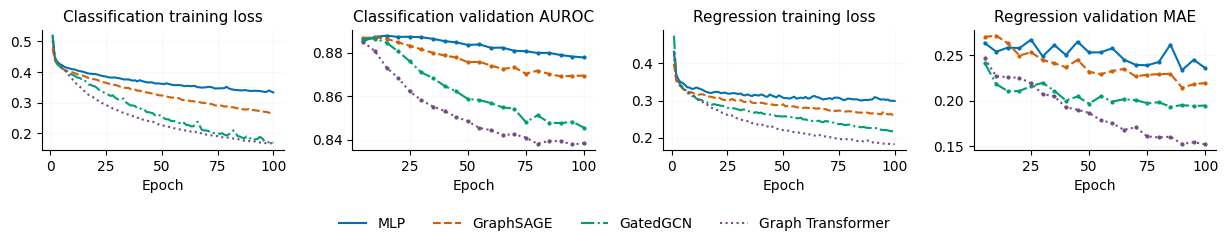

In [20]:
from src.history.report import plot_history_training_summary

figure, axes = plt.subplots(1, 4, figsize=(12.4, 2.45))
plot_history_training_summary(full_history_root, "classification", axes=axes[:2], show_legend=False)
plot_history_training_summary(full_history_root, "regression", axes=axes[2:], show_legend=False)
axes[0].set_title("Classification training loss")
axes[1].set_title("Classification validation AUROC")
axes[2].set_title("Regression training loss")
axes[3].set_title("Regression validation MAE")
figure.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
figure.tight_layout(rect=(0, 0.13, 1, 1))
display(figure)
plt.close(figure)


*Training loss and validation score by epoch for classification (left two panels) and count regression (right two panels). Lines show the mean across three seeds for each architecture.*

### 5.5 RQ3: Effect of Model Architecture Across Input Configurations

Sections 5.2–5.4 establish baseline performance and the effects of OSM and history separately. This section focuses on differences between architectures, using the combined-input results and changes in architecture rankings across the four configurations in Table 5.1. Classification and regression use separately trained models.

#### 5.5.1 Combined-Input Classification: Overall Ranking and Hotspot Screening

With all inputs combined, MLP has the highest mean AUROC (0.8878), followed by GraphSAGE (0.8877), GatedGCN (0.8868) and Graph Transformer (0.8856). The unrounded MLP-GraphSAGE gap is approximately 0.00013, smaller than GraphSAGE's seed standard deviation (0.00047). MLP does not outperform GraphSAGE on AUROC in every same-seed comparison, so the means do not establish a reliable separation between the leading pair.

GraphSAGE leads the metrics most directly related to screening: AP is 0.3261, compared with 0.3243 for GatedGCN, 0.3203 for Graph Transformer and 0.3199 for MLP. Its top-1% precision and recall are also highest, at 55.79% and 14.92%, respectively. Relative to MLP, its shortlist contains about 1.6 more accident-positive roads per 100 selected roads. GraphSAGE has higher AP and top-1% precision than each alternative in all three same-seed comparisons, although this does not establish statistical significance or robustness beyond the evaluated setting.

#### 5.5.2 Combined-Input Regression: Overall Error and Accident-Positive Roads

Graph Transformer has the lowest overall MAE (0.1564), followed by GatedGCN (0.1764), GraphSAGE (0.1999) and MLP (0.2235). This ordering holds in each same-seed comparison. The Transformer's advantage over GatedGCN is approximately 0.0199 accidents per road-month in the mean.

The ordering reverses on accident-positive road-months: MAE is lowest for MLP (0.4339), followed by GraphSAGE (0.4439), GatedGCN (0.5060) and Graph Transformer (0.5661). On zero-accident road-months, the respective errors are 0.2153, 0.1904, 0.1635 and 0.1405. This extends the history-only subgroup analysis in Section 5.4.1 to an architecture comparison with combined inputs: the Transformer leads overall by reducing errors on the much larger zero-count group, while MLP is more accurate where accidents occur.

#### 5.5.3 What Changes When the Inputs Are Combined?

The separate-addition results in Sections 5.3 and 5.4 do not establish whether using both feature groups is preferable. Adding OSM to history increases mean AUROC by 0.0020 for MLP, 0.0016 for GraphSAGE, 0.0020 for GatedGCN and 0.0019 for Graph Transformer. AP and top-1% precision and recall also increase in the mean for every architecture. Thus, combined inputs produce each classifier's highest mean scores, although the small increments over history alone warrant caution with three seeds.

For regression, adding OSM to history reduces mean MAE for GraphSAGE (0.2107 to 0.1999) and GatedGCN (0.1891 to 0.1764), but increases it for MLP (0.2199 to 0.2235) and Graph Transformer (0.1530 to 0.1564). The best count configuration in Table 5.1 is therefore Graph Transformer with history alone, rather than all inputs combined. These comparisons establish that combining features can change performance differently across architectures; they do not identify a feature-interaction mechanism.

#### 5.5.4 Interpreting Architecture Differences

**MLP and GraphSAGE: direct features versus additional propagation.** The Node2Vec and engineered-history explanations in Sections 5.3.2 and 5.4.1 help account for MLP's competitive ranking. The architectural distinction is how the models use information beyond the target road: GraphSAGE incorporates connecting-road attributes into neighbourhood messages, whereas MLP uses the supplied endpoint and road vectors directly (Sections 4.3.1–4.3.2). With history present, GraphSAGE can propagate historical road information through its two graph layers in addition to receiving the predefined neighbour-history summaries. Its stronger AP and screening results are consistent with a benefit from this additional aggregation. Testing that explanation would require retaining history in the prediction head while removing it from graph messages and retraining.

**GatedGCN: learned gates versus uniform averaging.** GatedGCN can vary neighbouring roads' contributions through feature-wise gates and evolving edge states (Section 4.3.3). Its lead in baseline and OSM-only count MAE does not extend to the history configurations, and its adaptive weighting does not surpass GraphSAGE's history-based screening. The extra flexibility therefore changes performance without providing a consistent advantage. The scores do not show which roads its gates emphasise or establish that gating causes the observed differences.

**Graph Transformer: selective spatial aggregation, not temporal attention.** Its attention scores depend on endpoint representations and connecting-road attributes (Section 4.3.4). History can therefore affect the weighting of neighbouring intersections, offering a possible explanation for its stronger regression performance in the history configurations. However, this is local attention over the road graph: the model receives historical summaries and does not attend over a sequence of past months. The subgroup reversal in Section 5.5.2 also limits the interpretation of its overall MAE: flexible attention is not evidence of uniformly better count estimates. Isolating its contribution would require an otherwise matched uniform-attention control; inspecting attention weights alone would not establish their causal effect.

#### 5.5.5 Contribution of the Added Architectures and Answer to RQ3

GatedGCN and Graph Transformer, neither evaluated in the original paper, broaden the comparison beyond the selected MLP and GraphSAGE reproduction baselines. Both achieve lower mean overall count MAE than those baselines in every input configuration, but neither consistently improves classification. Their addition reveals a task-dependent benefit: adaptive graph encoders are competitive for overall count error, while the simpler GraphSAGE provides the strongest combined-input screening and MLP remains competitive on AUROC.

These are comparisons of complete implementations under the shared Delaware protocol and one fixed Node2Vec embedding. Gating and attention are not isolated from parameter counts, normalisation or other transformations, and three seeds do not establish statistical significance. The answer to RQ3 is therefore conditional on the inputs and evaluation objective: the added models improve overall count MAE, but greater architectural flexibility does not consistently improve accident-occurrence ranking or performance on accident-positive roads.



## 6. Limitations and Future Work



### 6.1 Temporal Validity and Missing Data

The 2026 OSM snapshot postdates the 2009–2022 accidents: later road changes, potentially introduced in response to crashes, may appear in earlier predictions and overstate forecasting performance. Historical snapshots should be matched to target years. Past-only accident history also assumes timely, complete reporting; withholding recent source months would test sensitivity to reporting delays. Traffic volume covers only 3.16% of physical roads, and several OSM attributes are concentrated on well-mapped major roads. Missing-value indicators cannot replace exposure data; road inventories and fuller traffic counts would strengthen interpretation.



### 6.2 Generalisation and Experimental Scope

Later-month evaluation on Delaware's existing network does not establish performance on unseen roads or other states. Full-network static OSM standardisation assumes a known network, whereas temporal scalers use training-period data. Spatial holdouts should fit preprocessing on training roads and specify how new-network Node2Vec embeddings are generated and aligned.

Three model seeds with one fixed embedding measure limited training variability, excluding embedding, geographic and split uncertainty. More seeds, independent embeddings and chronological windows are needed, with temporal block resampling where appropriate. Shared hidden widths and training budgets do not equalise parameter counts or optimise each architecture; results concern these implementations. Broader tuning under a declared compute budget would strengthen model-family comparisons.



### 6.3 Feature Design and Interpretation

Overlapping history summaries discard event ordering and can be redundant. Recency-weighted counts, time since the last accident or sequence models could retain more temporal information. Equal weighting of roads sharing a junction also ignores traffic relationships; geometry-aware neighbour summaries could test more selective spatial context (Huang et al., 2023).

Permutation importance measures fitted-model reliance. Correlated features can substitute for one another, and shuffling alters their joint distribution, so importance values are neither additive nor causal. Retraining ablations would complement this analysis; complete-architecture comparisons likewise cannot attribute gains specifically to gating or attention.



### 6.4 Evaluation and Operational Use

Balanced training changes class prevalence, and calibration is untested: classifier outputs support ranking, rather than validated accident probabilities. Calibration requires separate validation before probability-based use. Zero-count road-months dominate MAE, so overall improvements can conceal worse errors on accident-positive roads. Subgroup errors, AP and top-risk screening metrics should accompany overall MAE; stratifying by recent history would test benefits on roads without recurring crashes.

Finally, retrospective accuracy does not establish accident prevention. The map supports exploration; practical deployment requires prospective evaluation incorporating reporting delays, inspection budgets and intervention outcomes.


## 7. Conclusion

This modified reproduction of ML4RoadSafety evaluates four architectures across baseline, OSM, history and combined inputs for monthly accident occurrence and counts in Delaware, supported by implemented feature pipelines and an interactive risk map.

For RQ1, OSM improves all four models: AUROC rises by 0.002–0.003 and count MAE falls by approximately 3–6%. Nearby-place features show the greatest permutation sensitivity. GraphSAGE's larger OSM gain without Node2Vec (0.025) is consistent with overlapping predictive information. For RQ2, history consistently improves occurrence ranking, while count-error effects depend on architecture.

For RQ3, GraphSAGE with OSM and history provides the strongest hotspot screening, with AUROC nearly tied with MLP. Graph Transformer with history alone achieves the lowest overall count MAE (0.1530), beating its combined-input setting (0.1564). Both added architectures improve mean overall count MAE over MLP and GraphSAGE in every input setting, without consistent classification gains. The combined-input Transformer's lower overall error accompanies higher error on accident-positive roads, underscoring the need to choose models by decision objective.

These findings are conditional on a known Delaware network, three seeds and retrospective map inputs. Historical maps, reporting-delay checks and geographic and temporal holdouts are needed to assess practical forecasting value.


## 8. References

Ahmad, N., Wali, B., Khattak, A. J., & Dumbaugh, E. (2021). Built environment, driving errors and violations, and crashes in naturalistic driving environment. Accident Analysis & Prevention, 157, 106158.

Boeing, G. (2025). Modeling and analyzing urban networks and amenities with OSMnx. Geographical Analysis.

Bresson, X., & Laurent, T. (2017). Residual gated graph convnets. arXiv Preprint arXiv:1711.07553.

Briz-Redón, A., Iftimi, A., & Montes, F. (2022). Accounting for previous events to model and predict traffic accidents at the road segment level: A study in Valencia (Spain). Physica A: Statistical Mechanics and Its Applications, 585, 126416.

Castillo, R. C., Staguhn, E. D., & Weston-Farber, E. (2020). The effect of state-level stay-at-home orders on COVID-19 infection rates. American Journal of Infection Control, 48(8), 958–960.

Dwivedi, V. P., & Bresson, X. (2020). A generalization of transformer networks to graphs. arXiv Preprint arXiv:2012.09699.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. Journal of Machine Learning Research, 20(177), 1–81.

Gao, X., Jiang, X., Haworth, J., Zhuang, D., Wang, S., Chen, H., & Law, S. (2024). Uncertainty-aware probabilistic graph neural networks for road-level traffic crash prediction. Accident Analysis & Prevention, 208, 107801.

Geofabrik GmbH, & OpenStreetMap contributors. (2026). Delaware OpenStreetMap extract, 18 October 2026 (delaware-261018.osm.pbf) [Data set]. Open Database Licence 1.0. https://download.geofabrik.de/north-america/us/delaware.html

Goodchild, M. F., & Hunter, G. J. (1997). A simple positional accuracy measure for linear features. International Journal of Geographical Information Science, 11(3), 299–306. https://doi.org/10.1080/136588197242419

Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 855–864.

Guerra, A., Gadhiya, V., & Srisurin, P. (2022). Crash prediction on road segments using machine learning methods. ASEAN Engineering Journal, 12(3), 27–37.

Haklay, M. (2010). How good is volunteered geographical information? A comparative study of OpenStreetMap and Ordnance Survey datasets. Environment and Planning B: Planning and Design, 37(4), 682–703. https://doi.org/10.1068/b35097

Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. Advances in Neural Information Processing Systems, 30.

Huang, B., Hooi, B., & Shu, K. (2023). TAP: A Comprehensive Data Repository for Traffic Accident Prediction in Road Networks. arXiv Preprint arXiv:2304.08640.

Kashifi, M. T., Al-Turki, M., & Sharify, A. W. (2023). Deep hybrid learning framework for spatiotemporal crash prediction using big traffic data. International Journal of Transportation Science and Technology, 12(3), 793–808.

Kingma, D. P., & Ba, J. (2014). Adam: A method for stochastic optimization. arXiv Preprint arXiv:1412.6980.

Ma, Z., Zhang, H., Steven, I., Chien, J., Wang, J., & Dong, C. (2017). Predicting expressway crash frequency using a random effect negative binomial model: A case study in China. Accident Analysis & Prevention, 98, 214–222.

MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. Journal of Econometrics, 29(3), 305–325.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv Preprint arXiv:1301.3781.

Nippani, A., Li, D., Ju, H., Koutsopoulos, H., & Zhang, H. (2023). Graph Neural Networks for Road Safety Modeling: Datasets and Evaluations for Accident Analysis. Advances in Neural Information Processing Systems Datasets and Benchmarks Track, 36.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. Advances in Neural Information Processing Systems, 30.

Wijnen, W., & Stipdonk, H. (2016). Social costs of road crashes: An international analysis. Accident Analysis & Prevention, 94, 97–106.

## 9. Team Contributions

| Member | Role | Sections | Code and notebooks |
|---|---|---|---|
| Aaron Teo Rui Kang | Original Data and Map | Data and Exploration (benchmark, EDA, interactive map) | `src/eda.py`, `src/visualization/risk_map.py` |
| Cheong Fung Wei | Baseline Models and Evaluation | Methodology (prediction tasks, baseline models); Experimental Setup; Results (baselines) | `src/model/`, `src/eval/`, `notebooks/train_baseline+gated_gcn+graph_transformer.ipynb` |
| Duggal Vidurveer | OpenStreetMap Features | 3.2 OpenStreetMap Road Context; 4.2.3 OpenStreetMap Features; 4.4.2 Adding OSM; 5.3 RQ1: Effect of OSM Features; 6.1 (OSM limitations); Appendix A | `src/osm/`, `notebooks/osm_features_and_eda.ipynb`, `notebooks/osm_baseline_comparison.ipynb`, `notebooks/osm_node2vec_density_check.ipynb` |
| Liu Jing Jing | Accident History Features | Accident-history construction and EDA; history features (Methodology); accident-history experiments (Experimental Setup, Results and Discussion); accident-history limitations | `src/history/`, `src/data/history.py`, `notebooks/accident_history_eda.ipynb`, `notebooks/train_accident_history.ipynb`, `results/history_100_epochs/` |
| Jason Ciu Putra Sung | Additional Models and Evaluation | GatedGCN & Graph Transformers Implementation, RQ3 | `src/model/gatedgcn/`, `src/model/graph_transformer/`, `notebooks/train_baseline+gated_gcn+graph_transformer.ipynb` |

## Appendix A. OpenStreetMap Features

### A.1 Feature Catalogue

| Group | Feature | Definition | OSM source | Type | Encoding | Roads with a value |
|---|---|---|---|---|---|---|
| Road character | Speed limit | Posted limit of the matched road (highest if several) | `maxspeed` | mph | standardised, indicator | 13.9% |
| Road character | Number of lanes | Lane count of the matched road (highest if several) | `lanes` | count | limited to 1–8, standardised, indicator | 12.6% |
| Road character | Surface | asphalt, concrete, gravel, paved, unpaved, mixed, other | `surface` | category | one-hot, indicator | 17.3% |
| Road character | Bridge | Road is mapped as a bridge | `bridge` | 0/1 | as is | 89.6% |
| Road character | Tunnel | Road is mapped as a tunnel | `tunnel` | 0/1 | as is | 89.6% |
| Intersection control | Control at road ends (8 features) | Signal, stop sign, give-way sign or crossing at the start or end node | `highway=traffic_signals`, `stop`, `give_way`, `crossing`; `crossing=*` | 0/1 | as is (give-way features dropped: no variation) | 89.6% |
| Intersection control | Roundabout | Road is part of a roundabout | `junction=roundabout`, `circular` | 0/1 | as is | 89.6% |
| Intersection control | Control between junctions (5 features) | Signals, stop signs, give-way signs, crossings and traffic-calming devices within 15 m of the road, removed by simplification | as above; `traffic_calming=*` | count | log(1 + x), standardised | 89.6% |
| Cycle, pedestrian, lighting | Cycle lane | A cycle lane is mapped on either side | `cycleway`, `cycleway:left/right/both` | yes / no / unknown | value and indicator | 2.4% |
| Cycle, pedestrian, lighting | Sidewalk | A sidewalk is mapped | `sidewalk` | yes / no / unknown | value and indicator | 1.5% |
| Cycle, pedestrian, lighting | Street lighting | The road is mapped as lit | `lit` | yes / no / unknown | value and indicator | 0.6% |
| Nearby places | Counts within 100, 250, 500 and 1,000 m (28 features) | Number of schools, bus stops, food outlets, bars, parking areas, crossings and signals around the road's midpoint | `amenity=school`, `restaurant`, `fast_food`, `bar`, `pub`, `parking`; `highway=bus_stop`; control points | count | log(1 + x), standardised | 100% |
| Nearby places | Distance to nearest (7 features) | Distance from the road's midpoint to the nearest point of each kind | as above | metres | log(1 + x), standardised | 100% |
| Road shape | Curvature ratio | Road length divided by the straight-line distance between its ends | benchmark geometry | ratio | limited to 1–5, standardised, indicator | 99.4% |
| Matching | Unmatched indicator | Road has no OSM match | matching step | 0/1 | as is | 100% |

*Table A1. Complete catalogue of the 58 OpenStreetMap features (70 encoded columns) for Delaware. "OSM source" gives the OpenStreetMap key from which each feature is derived, so that the extraction can be reproduced. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 6, 7.1 and 13.*

Two construction details are recorded here for completeness. First, standard simplification of the OSM network into a graph removes nodes that are not junctions, together with any control point mapped on them; in Delaware this removed 39% of traffic signals, 84% of stop signs and more than 99% of crossings and traffic-calming devices. These points were recovered from the raw extract and assigned to the nearest road within 15 m, giving the "between junctions" counts. Second, to limit the influence of likely mapping errors, lane counts were restricted to 1–8 and the curvature ratio to 1–5; surfaces recorded on fewer than 50 roads were grouped as "other", standardised values were limited to ±10 standard deviations, and missing-value indicators were added for features missing on more than 0.5% of matched roads. The full construction, with diagnostics, is in `notebooks/osm_features_and_eda.ipynb` (Stages 6–7 and 13).

### A.2 Gap-Filling Test for Incomplete Attributes

For a road with a missing speed limit, number of lanes or surface, an estimate was taken from neighbouring roads of the same road type, that is, roads that share a junction with it. For the speed limit and the number of lanes, the estimate was the average of the neighbours' values, rounded to the nearest 5 mph or whole lane; for the surface, it was their most common value. Where no neighbour had a recorded value, the most common value for the road type was used. To test the method, one fifth of the recorded values were hidden, estimated from the remaining values and compared with the true values, and this was repeated for each fifth. A speed estimate counted as correct if it was within 5 mph of the true value, and a lane or surface estimate if it matched exactly. The method was accepted for an attribute only if it was at least 60% accurate and at least five percentage points more accurate than assigning the most common value in the state. Because recorded values come mainly from well-mapped major roads, the 60% threshold also had to hold for the expected accuracy on roads where the value is actually missing. The speed limit passed, while the number of lanes and the surface did not (Table A2).

| Attribute | Recorded on (roads / accidents) | Most common value in state | Road type | Neighbours and road type | Expected on missing roads | Decision |
|---|---|---|---|---|---|---|
| Speed limit (within 5 mph) | 13.9% / 43.8% | 29.1% | 64.4% | 96.3% | 63.5% | Passed |
| Number of lanes (exact) | 12.6% / 49.8% | 63.8% | 63.8% | 73.2% | 55.0% | Failed: expected accuracy below 60% |
| Surface (exact) | 17.3% / 26.8% | 94.9% | 94.9% | 97.1% | n/a | Failed: improvement below 5 points |

*Table A2. Validation of gap-filling for the three most incomplete road attributes in Delaware. The three middle columns give accuracy on hidden recorded values for each estimation method. For surface, the expected accuracy on missing roads was not evaluated because the method had already failed the improvement criterion. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 9.1 and 10.*

## Appendix B. Detailed History Checkpoint Tables

### B.1 Classification


In [ ]:
from src.history.report import history_checkpoints

checkpoints = history_checkpoints(full_history_root, "classification")
from IPython.display import HTML
display(HTML(checkpoints.to_html(index=False, float_format=lambda value: f"{value:.4f}")))

Model,Seed,Epoch,Validation AUROC,Test AUROC
MLP,0,15,0.8880,0.8862
MLP,1,15,0.8877,0.8860
MLP,2,30,0.8875,0.8850
GraphSAGE,0,10,0.8876,0.8862
GraphSAGE,1,10,0.8875,0.8861
GraphSAGE,2,5,0.8869,0.8858
GatedGCN,0,5,0.8865,0.8849
GatedGCN,1,10,0.8867,0.8848
GatedGCN,2,5,0.8861,0.8846
Graph Transformer,0,5,0.8854,0.8842


### B.2 Count regression


In [ ]:
checkpoints = history_checkpoints(full_history_root, "regression")
from IPython.display import HTML
display(HTML(checkpoints.to_html(index=False, float_format=lambda value: f"{value:.4f}")))

Model,Seed,Epoch,Validation MAE,Test MAE
MLP,0,100,0.2165,0.2168
MLP,1,90,0.2156,0.2158
MLP,2,70,0.2271,0.2272
GraphSAGE,0,90,0.1929,0.1940
GraphSAGE,1,100,0.2083,0.2114
GraphSAGE,2,95,0.2242,0.2266
GatedGCN,0,65,0.1952,0.1978
GatedGCN,1,95,0.1912,0.1963
GatedGCN,2,85,0.1718,0.1732
Graph Transformer,0,90,0.1461,0.1502
